In [1]:
!pip install scanpy

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 14.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.0/12.0 MB 69.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.3 MB/s  0:00:00
  Attempting uninstall: pandas
    Found existing installation: pandas 2.2.3
    Uninstalling pandas-2.2.3:
      Successfully uninstalled pandas-2.2.3
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13/13 [scanpy]
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-colab 1.0.0 requires pandas==2.2.3, but you have pandas 3.1.0 which is incompatible.


In [2]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Scanpy version:", sc.__version__)

/usr/local/lib/python3.13/dist-packages/pandas/core/arrays/masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Scanpy version: 1.12.5


/tmp/ipykernel_846/1937688731.py:6: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy version:", sc.__version__)


In [3]:
adata = sc.datasets.pbmc3k()

print(adata)

  0%|          | 0.00/5.58M [00:00<?, ?B/s]

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)


In [4]:
# Number of cells and genes
print("Number of cells:", adata.n_obs)
print("Number of genes:", adata.n_vars)

# First 5 cells
print(adata.obs.head())

# First 5 genes
print(adata.var.head())

Number of cells: 2700
Number of genes: 32738
Empty DataFrame
Columns: []
Index: [AAACATACAACCAC-1, AAACATTGAGCTAC-1, AAACATTGATCAGC-1, AAACCGTGCTTCCG-1, AAACCGTGTATGCG-1]
                     gene_ids
index                        
MIR1302-10    ENSG00000243485
FAM138A       ENSG00000237613
OR4F5         ENSG00000186092
RP11-34P13.7  ENSG00000238009
RP11-34P13.8  ENSG00000239945


In [5]:
print(adata)

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X)


In [6]:
# Identify mitochondrial genes
adata.var["mt"] = adata.var_names.str.startswith("MT-")

# Calculate quality metrics
sc.pp.calculate_qc_metrics(
    adata,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

# Display QC information
adata.obs[
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
].head()

,n_genes_by_counts,total_counts,pct_counts_mt
index,,,
AAACATACAACCAC-1,781,2421.0,3.015283
AAACATTGAGCTAC-1,1352,4903.0,3.793596
AAACATTGATCAGC-1,1131,3149.0,0.889171
AAACCGTGCTTCCG-1,960,2639.0,1.743085
AAACCGTGTATGCG-1,522,981.0,1.223242


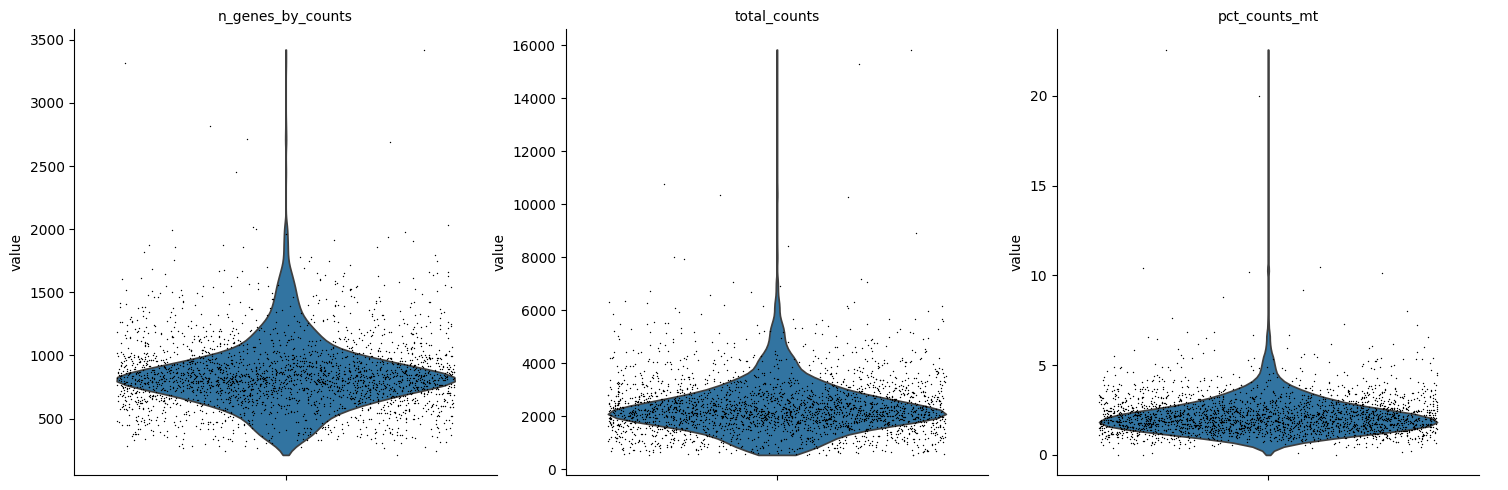

In [7]:
sc.pl.violin(
    adata,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True
)

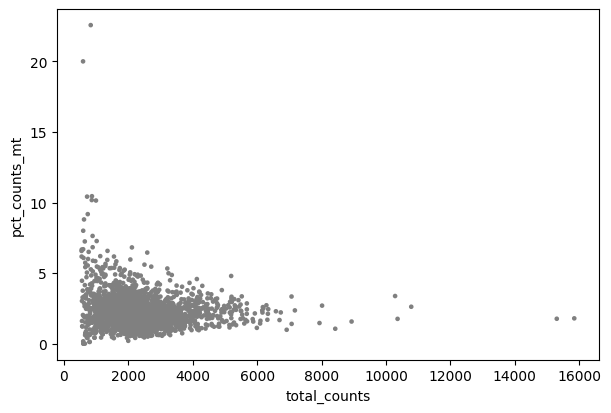

In [8]:
sc.pl.scatter(
    adata,
    x="total_counts",
    y="pct_counts_mt"
)

In [9]:
# Filter cells
adata = adata[
    (adata.obs["n_genes_by_counts"] >= 200) &
    (adata.obs["n_genes_by_counts"] <= 2500) &
    (adata.obs["pct_counts_mt"] < 5)
].copy()

print(adata)

AnnData object with n_obs × n_vars = 2638 × 32738
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    layers: None (.X)


In [10]:
# Normalize each cell to 10,000 counts
sc.pp.normalize_total(adata, target_sum=1e4)

# Log transformation
sc.pp.log1p(adata)

print(adata)

AnnData object with n_obs × n_vars = 2638 × 32738
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    uns: 'log1p'
    layers: None (.X)


In [11]:
# Identify the 2,000 most variable genes
sc.pp.highly_variable_genes(
    adata,
    n_top_genes=2000,
    flavor="seurat"
)

print(
    "Highly variable genes:",
    adata.var["highly_variable"].sum()
)

Highly variable genes: 2000


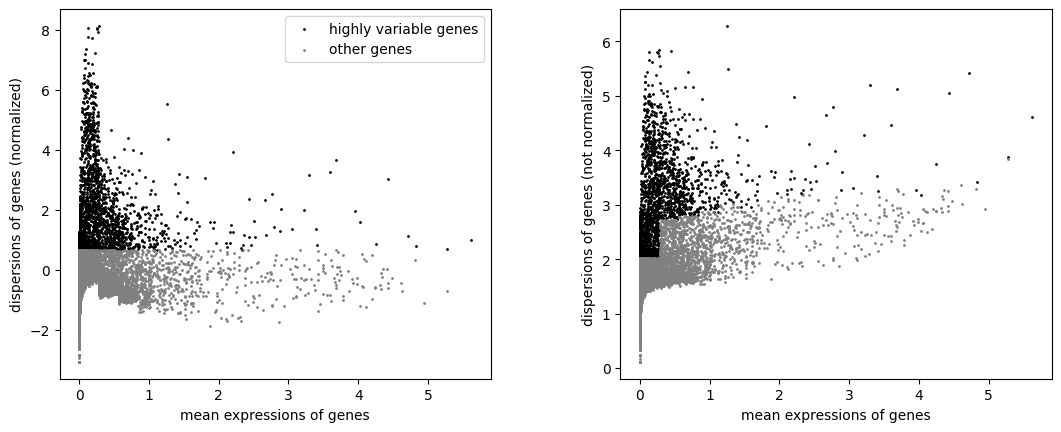

In [12]:
sc.pl.highly_variable_genes(adata)

In [13]:
# Store normalized, log-transformed data
adata.raw = adata

# Keep only highly variable genes
adata = adata[:, adata.var["highly_variable"]].copy()

print(adata)

AnnData object with n_obs × n_vars = 2638 × 2000
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts', 'highly_variable', 'means', 'dispersions', 'dispersions_norm'
    uns: 'log1p', 'hvg'
    layers: None (.X)


In [14]:
sc.pp.scale(adata, max_value=10)

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


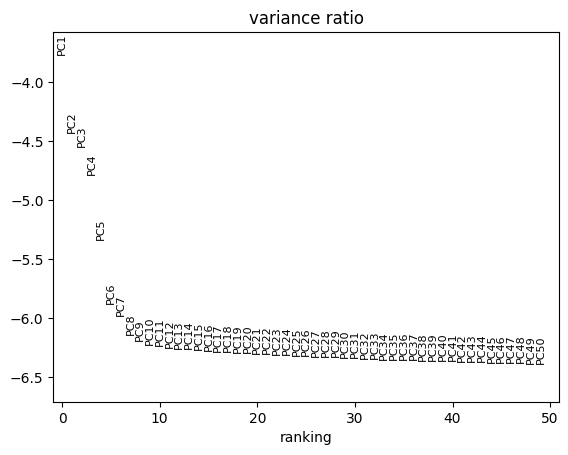

In [15]:
sc.tl.pca(
    adata,
    n_comps=50,
    svd_solver="arpack"
)

sc.pl.pca_variance_ratio(
    adata,
    n_pcs=50,
    log=True
)

In [16]:
sc.pp.neighbors(
    adata,
    n_neighbors=15,
    n_pcs=30
)

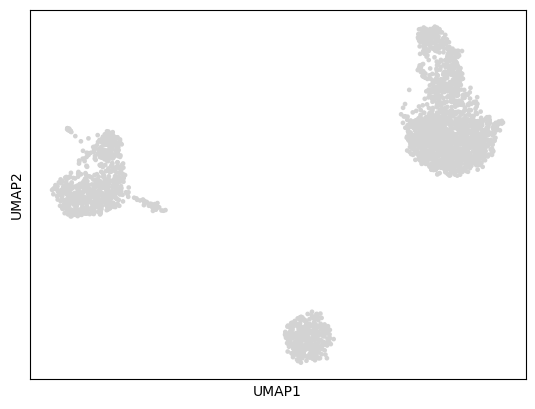

In [17]:
sc.tl.umap(adata)

sc.pl.umap(adata)

In [18]:
!pip install leidenalg igraph

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 19.2 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.7/5.7 MB 53.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [leidenalg]


In [19]:
sc.tl.leiden(
    adata,
    resolution=0.5,
    key_added="leiden",
    flavor="igraph"
)

print(adata.obs["leiden"].value_counts())

leiden
0    1173
2     639
3     433
1     344
4      36
5      13
Name: count, dtype: int64


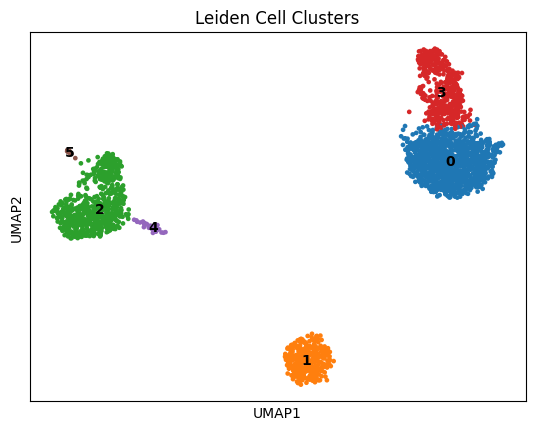

In [20]:
sc.pl.umap(
    adata,
    color="leiden",
    legend_loc="on data",
    title="Leiden Cell Clusters"
)

In [21]:
sc.tl.rank_genes_groups(
    adata,
    groupby="leiden",
    method="wilcoxon",
    use_raw=True
)

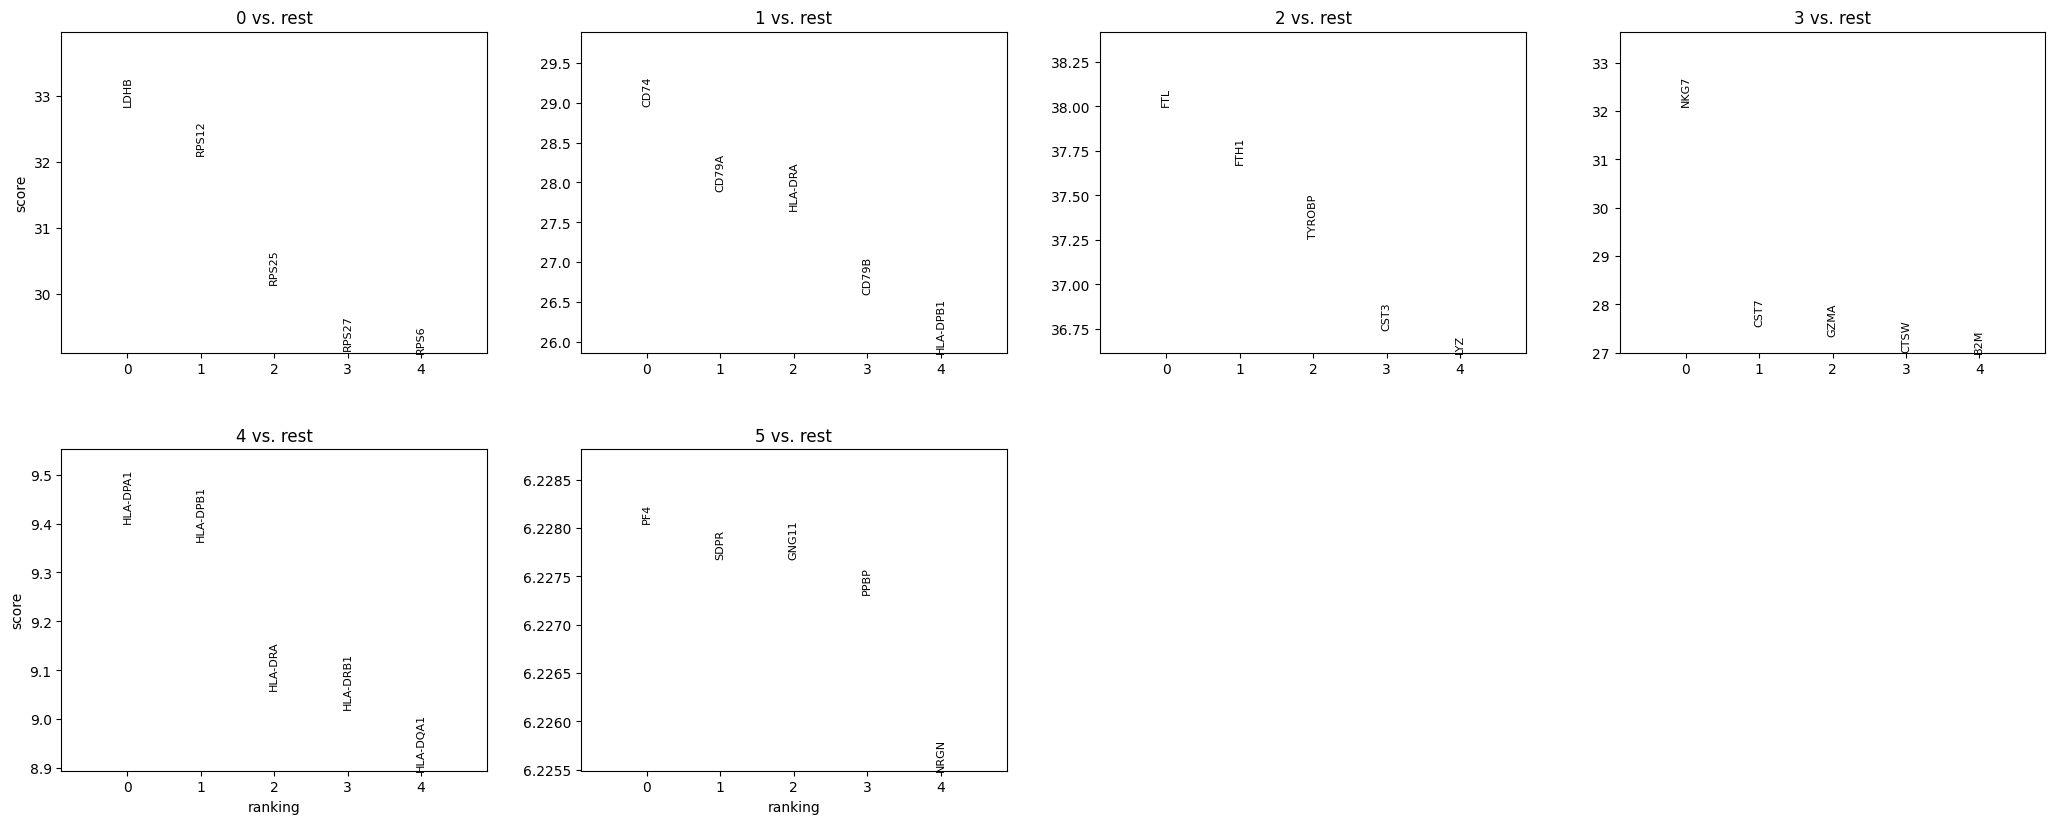

In [22]:
sc.pl.rank_genes_groups(
    adata,
    n_genes=5,
    sharey=False
)

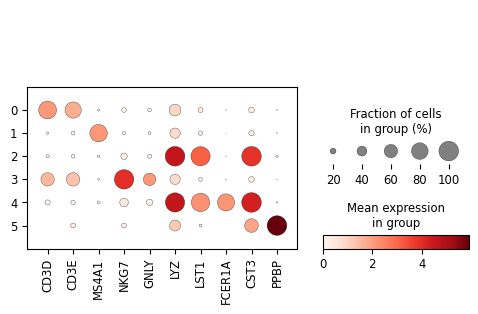

In [23]:
marker_genes = [
    "CD3D", "CD3E",      # T cells
    "MS4A1",             # B cells
    "NKG7", "GNLY",      # NK cells
    "LYZ", "LST1",       # Monocytes
    "FCER1A", "CST3",    # Dendritic cells
    "PPBP"               # Platelets
]

sc.pl.dotplot(
    adata,
    marker_genes,
    groupby="leiden",
    use_raw=True
)

In [24]:
cluster_labels = {
    "0": "T cells",
    "1": "B cells",
    "2": "Monocytes",
    "3": "NK-like cells",
    "4": "Dendritic/Myeloid-like",
    "5": "Platelets"
}

adata.obs["cell_type"] = (
    adata.obs["leiden"]
    .map(cluster_labels)
    .astype("category")
)

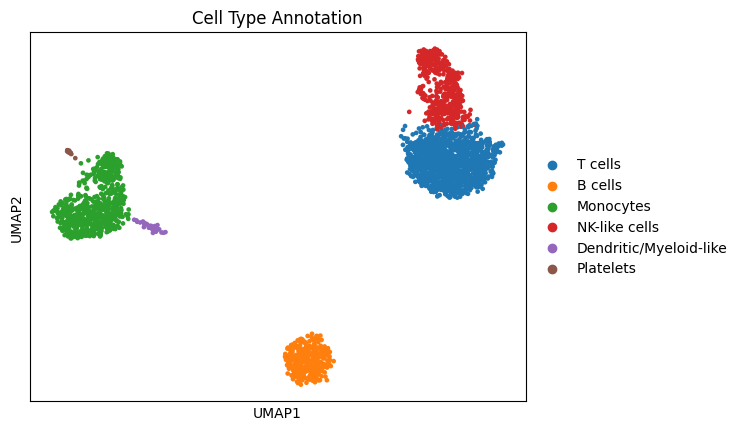

In [25]:
sc.pl.umap(
    adata,
    color="cell_type",
    title="Cell Type Annotation",
    legend_loc="right margin"
)

In [26]:
print(adata.obs["cell_type"].value_counts())

cell_type
T cells                   1173
Monocytes                  639
NK-like cells              433
B cells                    344
Dendritic/Myeloid-like      36
Platelets                   13
Name: count, dtype: int64


In [27]:
adata.write("pbmc3k_exploratory_processed.h5ad")

In [28]:
adata_pbmc3k = sc.datasets.pbmc3k()

# Ensure gene names are unique
adata_pbmc3k.var_names_make_unique()

# Preserve raw counts
adata_pbmc3k.layers["counts"] = adata_pbmc3k.X.copy()

print(adata_pbmc3k)

AnnData object with n_obs × n_vars = 2700 × 32738
    var: 'gene_ids'
    layers: None (.X), 'counts'


In [29]:
!mkdir -p /content/data/pbmc10k_v3

!wget -q \
"https://cf.10xgenomics.com/samples/cell-exp/3.0.0/pbmc_10k_v3/pbmc_10k_v3_filtered_feature_bc_matrix.tar.gz" \
-O /content/pbmc10k_v3.tar.gz

!tar -xzf /content/pbmc10k_v3.tar.gz \
-C /content/data/pbmc10k_v3

!find /content/data/pbmc10k_v3 -maxdepth 2 -type d

/content/data/pbmc10k_v3
/content/data/pbmc10k_v3/filtered_feature_bc_matrix


In [30]:
adata_pbmc10k = sc.read_10x_mtx(
    "/content/data/pbmc10k_v3/filtered_feature_bc_matrix",
    var_names="gene_symbols",
    cache=True
)

adata_pbmc10k.var_names_make_unique()

# Preserve raw counts
adata_pbmc10k.layers["counts"] = adata_pbmc10k.X.copy()

print(adata_pbmc10k)

AnnData object with n_obs × n_vars = 11769 × 33538
    var: 'gene_ids', 'feature_types'
    layers: None (.X), 'counts'


In [31]:
# Identify mitochondrial genes
adata_pbmc10k.var["mt"] = (
    adata_pbmc10k.var_names.str.startswith("MT-")
)

# Calculate QC metrics
sc.pp.calculate_qc_metrics(
    adata_pbmc10k,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

# View metrics
adata_pbmc10k.obs[
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
].head()

,n_genes_by_counts,total_counts,pct_counts_mt
AAACCCAAGCGCCCAT-1,1087,2204.0,2.359347
AAACCCAAGGTTCCGC-1,4200,20090.0,6.590343
AAACCCACAGAGTTGG-1,1836,5884.0,10.757988
AAACCCACAGGTATGG-1,2216,5530.0,7.848101
AAACCCACATAGTCAC-1,1615,5106.0,10.830396


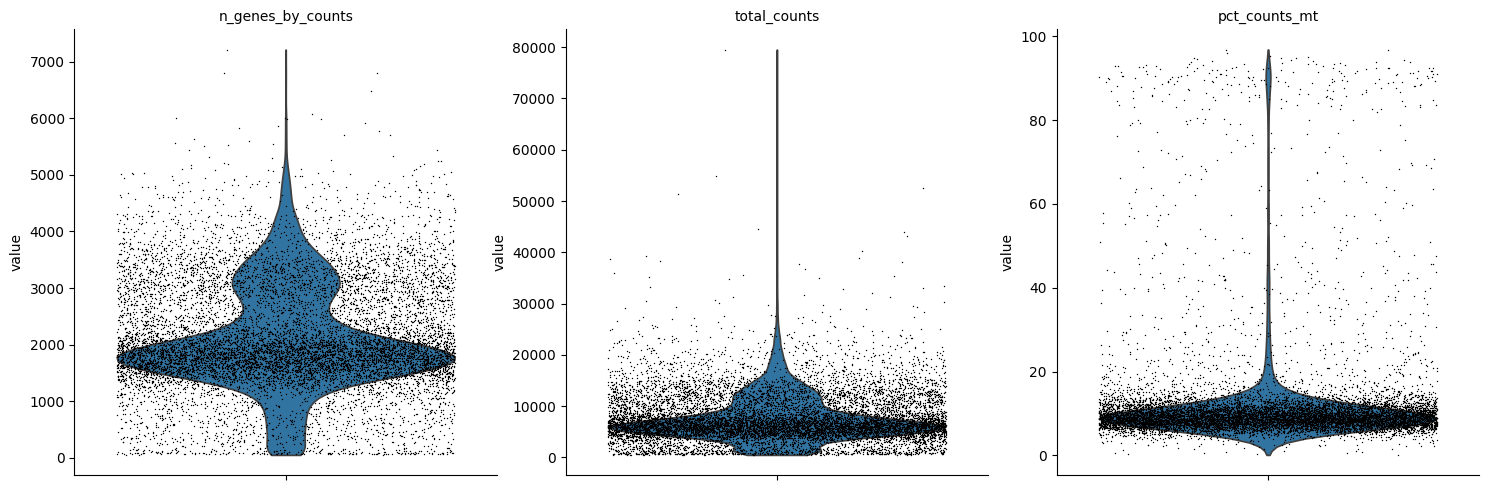

In [32]:
sc.pl.violin(
    adata_pbmc10k,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.4,
    multi_panel=True
)

In [33]:
adata_pbmc10k = adata_pbmc10k[
    (adata_pbmc10k.obs["n_genes_by_counts"] >= 200) &
    (adata_pbmc10k.obs["n_genes_by_counts"] <= 2500) &
    (adata_pbmc10k.obs["pct_counts_mt"] < 5)
].copy()

print(adata_pbmc10k)

AnnData object with n_obs × n_vars = 191 × 33538
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    layers: None (.X), 'counts'


In [34]:
adata_pbmc10k = sc.read_10x_mtx(
    "/content/data/pbmc10k_v3/filtered_feature_bc_matrix",
    var_names="gene_symbols",
    cache=True
)

adata_pbmc10k.var_names_make_unique()

adata_pbmc10k.layers["counts"] = adata_pbmc10k.X.copy()

adata_pbmc10k.var["mt"] = (
    adata_pbmc10k.var_names.str.startswith("MT-")
)

sc.pp.calculate_qc_metrics(
    adata_pbmc10k,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

In [35]:
adata_pbmc10k.obs[
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"]
].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.95, 0.99])

,n_genes_by_counts,total_counts,pct_counts_mt
count,11769.000000,11769.000000,11769.000000
mean,2109.421616,7644.850098,11.994768
std,940.065220,4709.125000,12.726960
min,54.000000,501.000000,0.137714
25%,1567.000000,4883.000000,7.703531
50%,1906.000000,6521.000000,9.145336
75%,2710.000000,9598.000000,11.099971
90%,3426.000000,13666.200000,14.356157
95%,3795.600000,16124.400000,25.077063
99%,4657.160000,23237.960000,88.956778


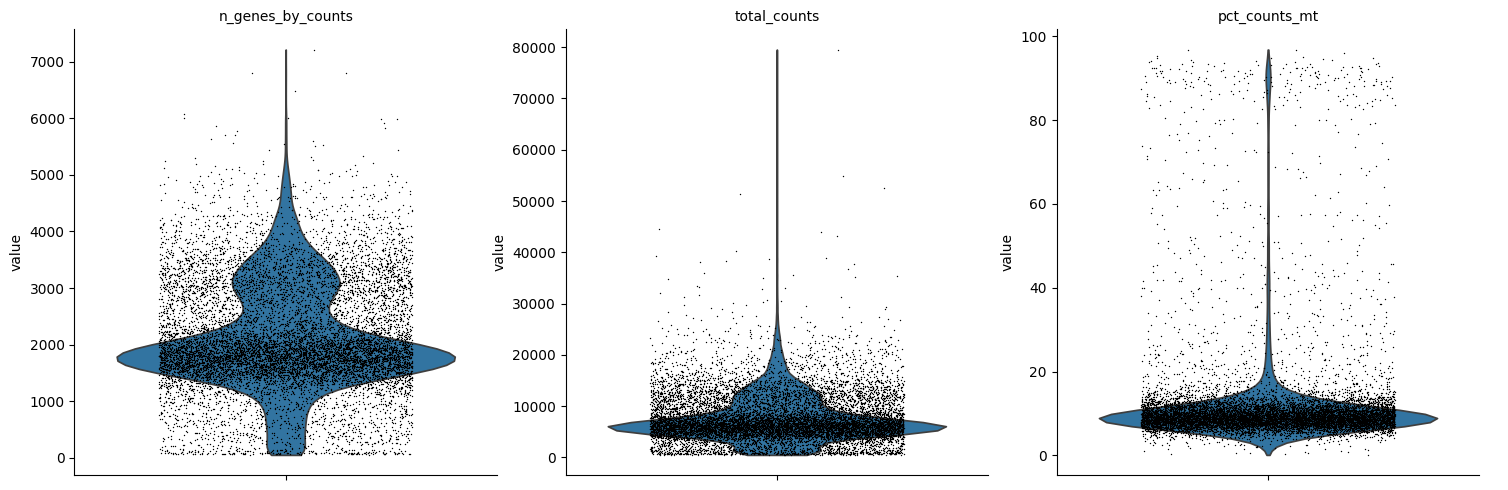

In [36]:
sc.pl.violin(
    adata_pbmc10k,
    ["n_genes_by_counts", "total_counts", "pct_counts_mt"],
    jitter=0.3,
    multi_panel=True
)

In [37]:
adata_pbmc10k = adata_pbmc10k[
    (adata_pbmc10k.obs["n_genes_by_counts"] >= 200) &
    (adata_pbmc10k.obs["n_genes_by_counts"] <= 5000) &
    (adata_pbmc10k.obs["pct_counts_mt"] < 15)
].copy()

print(adata_pbmc10k)

AnnData object with n_obs × n_vars = 10639 × 33538
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'feature_types', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    layers: None (.X), 'counts'


In [38]:
print(
    "Cells retained:",
    adata_pbmc10k.n_obs
)

print(
    "Percentage retained:",
    round(100 * adata_pbmc10k.n_obs / 11769, 2),
    "%"
)

Cells retained: 10639
Percentage retained: 90.4 %


In [39]:
# Calculate QC metrics for PBMC3k
adata_pbmc3k.var["mt"] = (
    adata_pbmc3k.var_names.str.startswith("MT-")
)

sc.pp.calculate_qc_metrics(
    adata_pbmc3k,
    qc_vars=["mt"],
    percent_top=None,
    log1p=False,
    inplace=True
)

# Apply the PBMC3k thresholds used earlier
adata_pbmc3k = adata_pbmc3k[
    (adata_pbmc3k.obs["n_genes_by_counts"] >= 200) &
    (adata_pbmc3k.obs["n_genes_by_counts"] <= 2500) &
    (adata_pbmc3k.obs["pct_counts_mt"] < 5)
].copy()

print(adata_pbmc3k)

AnnData object with n_obs × n_vars = 2638 × 32738
    obs: 'n_genes_by_counts', 'total_counts', 'total_counts_mt', 'pct_counts_mt'
    var: 'gene_ids', 'mt', 'n_cells_by_counts', 'mean_counts', 'pct_dropout_by_counts', 'total_counts'
    layers: None (.X), 'counts'


In [40]:
# Find genes present in both datasets
common_genes = sorted(
    set(adata_pbmc3k.var_names)
    .intersection(set(adata_pbmc10k.var_names))
)

print("Common genes:", len(common_genes))

Common genes: 20453


In [41]:
adata_pbmc3k = adata_pbmc3k[:, common_genes].copy()

adata_pbmc10k = adata_pbmc10k[:, common_genes].copy()

print("PBMC3k:", adata_pbmc3k.shape)
print("PBMC10k:", adata_pbmc10k.shape)

PBMC3k: (2638, 20453)
PBMC10k: (10639, 20453)


In [42]:
# Normalize and log-transform
sc.pp.normalize_total(adata_pbmc3k, target_sum=1e4)
sc.pp.log1p(adata_pbmc3k)

sc.pp.normalize_total(adata_pbmc10k, target_sum=1e4)
sc.pp.log1p(adata_pbmc10k)

# Select highly variable genes from reference
sc.pp.highly_variable_genes(
    adata_pbmc3k,
    n_top_genes=2000,
    flavor="seurat"
)

hvg = adata_pbmc3k.var_names[
    adata_pbmc3k.var["highly_variable"]
].tolist()

# Use same genes in both datasets
adata_pbmc3k = adata_pbmc3k[:, hvg].copy()
adata_pbmc10k = adata_pbmc10k[:, hvg].copy()

print(adata_pbmc3k.shape)
print(adata_pbmc10k.shape)

(2638, 2000)
(10639, 2000)


In [43]:
sc.pp.scale(adata_pbmc3k, max_value=10)

sc.tl.pca(adata_pbmc3k, n_comps=30)

sc.pp.neighbors(
    adata_pbmc3k,
    n_neighbors=15,
    n_pcs=30
)

sc.tl.leiden(
    adata_pbmc3k,
    resolution=0.5,
    key_added="cluster",
    flavor="igraph"
)

print(adata_pbmc3k.obs["cluster"].value_counts())

/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


cluster
0    1179
2     482
3     428
1     343
4     170
5      36
Name: count, dtype: int64


In [44]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report

import numpy as np

X = adata_pbmc3k.X
y = adata_pbmc3k.obs["cluster"].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

scaler = StandardScaler(with_mean=False)

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

model = LogisticRegression(
    max_iter=1000,
    class_weight="balanced"
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Reference held-out accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))

Reference held-out accuracy: 0.9753787878787878
              precision    recall  f1-score   support

           0       0.98      0.98      0.98       236
           1       1.00      1.00      1.00        69
           2       0.96      0.99      0.97        96
           3       0.98      0.95      0.96        86
           4       0.97      0.91      0.94        34
           5       0.75      0.86      0.80         7

    accuracy                           0.98       528
   macro avg       0.94      0.95      0.94       528
weighted avg       0.98      0.98      0.98       528



In [45]:
X_query = scaler.transform(adata_pbmc10k.X)

adata_pbmc10k.obs["predicted_cluster"] = model.predict(X_query)

print(
    adata_pbmc10k.obs["predicted_cluster"].value_counts()
)

predicted_cluster
2    3223
0    2434
3    2375
1    1479
4     973
5     155
Name: count, dtype: int64


/usr/lib/python3.13/functools.py:934: UserWarning: zero-centering a sparse array/matrix densifies it.
  return dispatch(args[0].__class__)(*args, **kw)


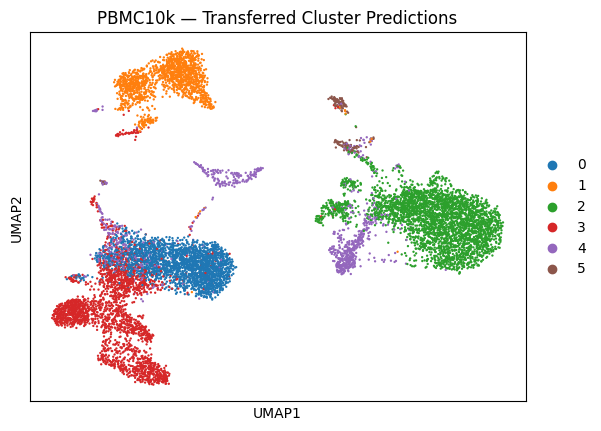

In [46]:
sc.pp.scale(adata_pbmc10k, max_value=10)

sc.tl.pca(adata_pbmc10k, n_comps=30)
sc.pp.neighbors(adata_pbmc10k, n_neighbors=15, n_pcs=30)
sc.tl.umap(adata_pbmc10k)

sc.pl.umap(
    adata_pbmc10k,
    color="predicted_cluster",
    title="PBMC10k — Transferred Cluster Predictions"
)

In [47]:
from sklearn.metrics import accuracy_score, f1_score

print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("Macro F1:", round(f1_score(y_test, y_pred, average="macro"), 4))
print("Weighted F1:", round(f1_score(y_test, y_pred, average="weighted"), 4))

Accuracy: 0.9754
Macro F1: 0.9436
Weighted F1: 0.9755


In [48]:
# Independently cluster PBMC10k
sc.tl.leiden(
    adata_pbmc10k,
    resolution=0.5,
    key_added="query_leiden",
    flavor="igraph"
)

# Compare transferred predictions with query clusters
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(
    adata_pbmc10k.obs["query_leiden"],
    adata_pbmc10k.obs["predicted_cluster"]
)

nmi = normalized_mutual_info_score(
    adata_pbmc10k.obs["query_leiden"],
    adata_pbmc10k.obs["predicted_cluster"]
)

print("ARI:", round(ari, 4))
print("NMI:", round(nmi, 4))

ARI: 0.6488
NMI: 0.7071


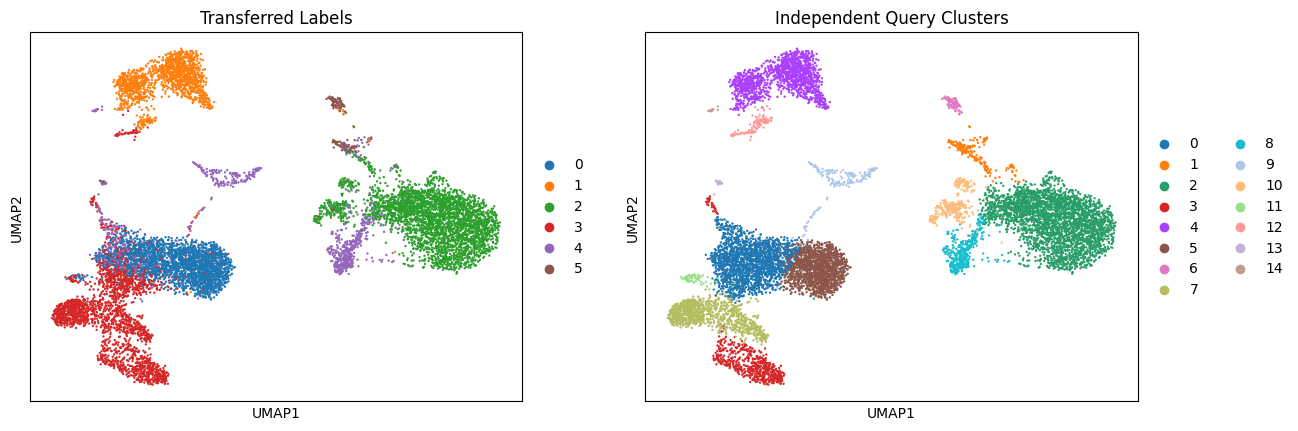

In [49]:
sc.pl.umap(
    adata_pbmc10k,
    color=["predicted_cluster", "query_leiden"],
    title=["Transferred Labels", "Independent Query Clusters"]
)

In [50]:
print("ARI:", round(ari, 4))
print("NMI:", round(nmi, 4))

ARI: 0.6488
NMI: 0.7071


In [51]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

print("PyTorch version:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

PyTorch version: 2.11.0+cpu
GPU available: False


In [52]:
import numpy as np
import torch

# Convert sparse matrices to dense arrays
X3 = adata_pbmc3k.X.toarray() if hasattr(adata_pbmc3k.X, "toarray") else np.asarray(adata_pbmc3k.X)
X10 = adata_pbmc10k.X.toarray() if hasattr(adata_pbmc10k.X, "toarray") else np.asarray(adata_pbmc10k.X)

# Combine datasets for exploratory unsupervised training
X = np.vstack([X3, X10]).astype(np.float32)

# Convert to PyTorch tensor
X_tensor = torch.tensor(X)

print("Combined data shape:", X_tensor.shape)

Combined data shape: torch.Size([13277, 2000])


In [53]:
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(2000, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 64)
        )

        self.decoder = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 512),
            nn.ReLU(),
            nn.Linear(512, 2000)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

model_ae = Autoencoder()

print(model_ae)

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=2000, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=2000, bias=True)
  )
)


In [54]:
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

class Autoencoder(nn.Module):
    def __init__(self):
        super().__init__()

        self.encoder = nn.Sequential(
            nn.Linear(2000, 512),
            nn.ReLU(),
            nn.Linear(512, 128),
            nn.ReLU(),
            nn.Linear(128, 64)
        )

        self.decoder = nn.Sequential(
            nn.Linear(64, 128),
            nn.ReLU(),
            nn.Linear(128, 512),
            nn.ReLU(),
            nn.Linear(512, 2000)
        )

    def forward(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

model_ae = Autoencoder()

print(model_ae)

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=2000, out_features=512, bias=True)
    (1): ReLU()
    (2): Linear(in_features=512, out_features=128, bias=True)
    (3): ReLU()
    (4): Linear(in_features=128, out_features=64, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=64, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=512, bias=True)
    (3): ReLU()
    (4): Linear(in_features=512, out_features=2000, bias=True)
  )
)


In [55]:
dataset = TensorDataset(X_tensor)

loader = DataLoader(
    dataset,
    batch_size=256,
    shuffle=True
)

criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model_ae.parameters(),
    lr=0.001
)

epochs = 10

for epoch in range(epochs):
    total_loss = 0

    for (batch,) in loader:
        optimizer.zero_grad()

        reconstructed = model_ae(batch)

        loss = criterion(reconstructed, batch)

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch+1}/{epochs}, "
        f"Loss: {total_loss / len(loader):.4f}"
    )

Epoch 1/10, Loss: 0.8131
Epoch 2/10, Loss: 0.7811
Epoch 3/10, Loss: 0.7714
Epoch 4/10, Loss: 0.7629
Epoch 5/10, Loss: 0.7553
Epoch 6/10, Loss: 0.7490
Epoch 7/10, Loss: 0.7429
Epoch 8/10, Loss: 0.7376
Epoch 9/10, Loss: 0.7328
Epoch 10/10, Loss: 0.7281


In [56]:

# Extract compressed representations
model_ae.eval()

with torch.no_grad():
    embeddings = model_ae.encoder(X_tensor).numpy()

print("Embedding shape:", embeddings.shape)


Embedding shape: (13277, 64)


In [57]:
n3 = adata_pbmc3k.n_obs

embeddings_3k = embeddings[:n3]
embeddings_10k = embeddings[n3:]

print("PBMC3k embeddings:", embeddings_3k.shape)
print("PBMC10k embeddings:", embeddings_10k.shape)

PBMC3k embeddings: (2638, 64)
PBMC10k embeddings: (10639, 64)


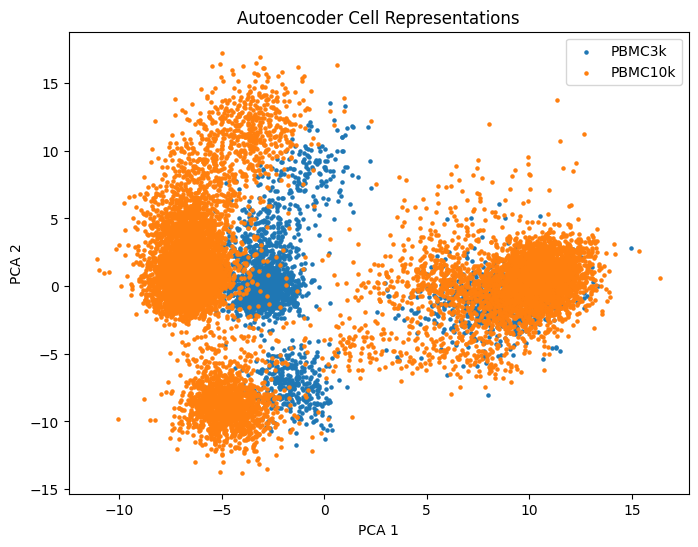

In [58]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2, random_state=42)

embeddings_2d = pca.fit_transform(embeddings)

plt.figure(figsize=(8, 6))

plt.scatter(
    embeddings_2d[:n3, 0],
    embeddings_2d[:n3, 1],
    s=5,
    label="PBMC3k"
)

plt.scatter(
    embeddings_2d[n3:, 0],
    embeddings_2d[n3:, 1],
    s=5,
    label="PBMC10k"
)

plt.xlabel("PCA 1")
plt.ylabel("PCA 2")
plt.title("Autoencoder Cell Representations")
plt.legend()
plt.show()

In [59]:
model_ae.eval()

with torch.no_grad():
    X3_tensor = torch.tensor(X3, dtype=torch.float32)
    X10_tensor = torch.tensor(X10, dtype=torch.float32)

    reconstructed_3k = model_ae(X3_tensor)
    reconstructed_10k = model_ae(X10_tensor)

    mse_3k = nn.MSELoss()(reconstructed_3k, X3_tensor).item()
    mse_10k = nn.MSELoss()(reconstructed_10k, X10_tensor).item()

print("PBMC3k Reconstruction MSE:", round(mse_3k, 4))
print("PBMC10k Reconstruction MSE:", round(mse_10k, 4))

PBMC3k Reconstruction MSE: 0.6984
PBMC10k Reconstruction MSE: 0.7269
